# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 6a: BiLSTM - Skema 1 "Embeddings"
Vocabulary kata dari train -> `nn.Embedding` 128-dim (acak, dilatih end-to-end) -> BiLSTM -> state akhir kedua arah -> Dropout -> Fully Connected -> softmax

Tokenisasi, vocabulary, dan embedding identik dengan Part 05a; yang berbeda hanya Encoding Layer.

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`
- Output: `outputs/bilstm_embeddings_val_results.json`, `outputs/models/bilstm_embeddings.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/bilstm_embeddings_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Skema 1: tokenisasi level kata, sama dengan baseline 04b (kata + tanda baca/emotikon jadi token sendiri)
TOKEN_PATTERN = r"\w+|[^\w\s]"
MIN_FREQ = 2 # token muncul < 2x di train -> <unk> (sama dengan MIN_COUNT di 04b)
MAX_LEN = 64 # panjang urutan tetap; lihat persentase terpotong di Step 2

# Hyperparameter tetap (tanpa tuning)
EMB_DIM = 128
HIDDEN_DIM = 128 # unit LSTM per arah (BiLSTM -> 256 setelah digabung)
CLIP_NORM = 1.0 # gradient clipping (standar untuk LSTM)
DROPOUT = 0.5
BATCH_SIZE = 64
EPOCHS = 15 # (rentang yang diminta: 10-15)
LR = 1e-3 # Adam


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train = torch.tensor([label_map[l] for l in train_df[LABEL_COL]], dtype=torch.long)
y_val   = torch.tensor([label_map[l] for l in val_df[LABEL_COL]],   dtype=torch.long)
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenisasi level kata & vocabulary (hanya dari train)
Indeks 0 = `<pad>`, indeks 1 = `<unk>`. Token di validation yang tidak ada di vocabulary train menjadi `<unk>`.

In [2]:
TOKEN_RE = re.compile(TOKEN_PATTERN)
def tokenize(text):
    return TOKEN_RE.findall(text)

train_tokens = [tokenize(t) for t in train_df[TEXT_COL]]
val_tokens = [tokenize(t) for t in val_df[TEXT_COL]]

# Vocabulary level kata: hanya dari train
counter = Counter(tok for t in train_tokens for tok in t)
itos = ["<pad>", "<unk>"] + sorted(w for w, c in counter.items() if c >= MIN_FREQ)
stoi = {w: i for i, w in enumerate(itos)}
PAD_IDX, UNK_IDX = stoi["<pad>"], stoi["<unk>"]
VOCAB_SIZE = len(itos)

# Vocabulary dibagi bersama TextCNN (Part 05a) dan BiLSTM (Part 06a)
# --> Simpan, atau cek identik jika sudah ada
vp = f"{DATA_DIR}/vocab_nn.json"
if os.path.exists(vp):
    with open(vp, encoding="utf-8") as f: old = json.load(f)["itos"]
    print("Vocabulary identik dengan vocab_nn.json yang sudah ada:", old == itos)
else:
    with open(vp, "w", encoding="utf-8") as f:
        json.dump({"itos": itos, "min_freq": MIN_FREQ, "token_pattern": TOKEN_PATTERN}, f, ensure_ascii=False)

def encode(tokens):
    ids = [stoi.get(t, UNK_IDX) for t in tokens][:MAX_LEN] # potong jika > MAX_LEN
    return ids + [PAD_IDX] * (MAX_LEN - len(ids)) # pad sampai MAX_LEN

X_train = torch.tensor([encode(t) for t in train_tokens], dtype=torch.long)
X_val = torch.tensor([encode(t) for t in val_tokens],   dtype=torch.long)

len_tok = np.array([len(t) for t in train_tokens])
tok_val_flat = [t for ts in val_tokens for t in ts]
cakupan_val = np.mean([t in stoi for t in tok_val_flat])
print(f"Ukuran vocabulary (termasuk <pad>, <unk>): {VOCAB_SIZE}")
print(f"Panjang token train: rata-rata {len_tok.mean():.1f} | persentil 95 = {np.percentile(len_tok, 95):.0f} | maks = {len_tok.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {(len_tok > MAX_LEN).mean()*100:.2f}%")
print(f"Cakupan token validation oleh vocabulary: {cakupan_val*100:.2f}%")
print("Bentuk tensor -> X_train:", tuple(X_train.shape), "| X_val:", tuple(X_val.shape))

Vocabulary identik dengan vocab_nn.json yang sudah ada: False
Ukuran vocabulary (termasuk <pad>, <unk>): 5716
Panjang token train: rata-rata 19.5 | persentil 95 = 51 | maks = 82
Teks train yang terpotong oleh MAX_LEN=64: 0.14%
Cakupan token validation oleh vocabulary: 85.55%
Bentuk tensor -> X_train: (4921, 64) | X_val: (1055, 64)


In [3]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256, shuffle=False)

### Step 3 - Arsitektur BiLSTM

In [4]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, num_classes, dropout, pad_idx):
        super().__init__()
        # Skema 1: embedding level kata, diinisialisasi acak dan ikut dilatih (end-to-end)
        # Bukan pre-trained
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.pad_idx = pad_idx
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, x): # x: (B, L)
        lengths = (x != self.pad_idx).sum(1).clamp(min=1).cpu() # panjang asli tiap teks (tanpa padding)
        e = self.embedding(x) # (B, L, emb_dim)
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed) # h: (2, B, hidden) = state akhir tiap arah
        h = torch.cat([h[0], h[1]], dim=1) # forward + backward -> (B, 2*hidden)
        return self.fc(self.dropout(h)) # logits; softmax ada di CrossEntropyLoss

model = BiLSTMClassifier(VOCAB_SIZE, EMB_DIM, HIDDEN_DIM, NUM_CLASSES, DROPOUT, PAD_IDX).to(device)
w0 = model.embedding.weight.detach().clone() # untuk bukti bahwa embedding ikut dilatih
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

with torch.no_grad():
    out = model(X_train[:4].to(device))
assert out.shape == (4, NUM_CLASSES)
print("Forward pass OK -> output:", tuple(out.shape))
print(f"Parameter yang dilatih: {n_params:,} (embedding: {model.embedding.weight.numel():,})")
print("Embedding trainable:", model.embedding.weight.requires_grad)

Forward pass OK -> output: (4, 6)
Parameter yang dilatih: 997,382 (embedding: 731,648)
Embedding trainable: True


### Step 4 - Training (satu run, tetap 15 epoch, model epoch terakhir yang dievaluasi)
Loss: `CrossEntropyLoss` (tanpa class weight)  
Optimizer Adam lr 1e-3  
Tidak memilih epoch terbaik di validation, supaya validation tidak dipakai untuk seleksi  
Akan ditunjukkan lewat grafik jika seandainya terjadi overfitting

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)   # hanya parameter yang dilatih

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/bilstm_embeddings.pt")

Epoch  1/15 | train loss 1.5615 acc 0.4017 | val loss 1.2274 acc 0.5573
Epoch  2/15 | train loss 1.0422 acc 0.6383 | val loss 0.9608 acc 0.6730
Epoch  3/15 | train loss 0.8072 acc 0.7228 | val loss 0.9186 acc 0.6853
Epoch  4/15 | train loss 0.6435 acc 0.7828 | val loss 0.9407 acc 0.6664
Epoch  5/15 | train loss 0.5174 acc 0.8279 | val loss 0.9726 acc 0.6815
Epoch  6/15 | train loss 0.4033 acc 0.8730 | val loss 1.0090 acc 0.6929
Epoch  7/15 | train loss 0.3025 acc 0.9092 | val loss 1.0697 acc 0.6730
Epoch  8/15 | train loss 0.2266 acc 0.9281 | val loss 1.0762 acc 0.6749
Epoch  9/15 | train loss 0.1611 acc 0.9522 | val loss 1.2511 acc 0.6777
Epoch 10/15 | train loss 0.1212 acc 0.9661 | val loss 1.2466 acc 0.6815
Epoch 11/15 | train loss 0.0857 acc 0.9770 | val loss 1.3645 acc 0.6777
Epoch 12/15 | train loss 0.0648 acc 0.9825 | val loss 1.4741 acc 0.6777
Epoch 13/15 | train loss 0.0528 acc 0.9884 | val loss 1.5257 acc 0.6664
Epoch 14/15 | train loss 0.0461 acc 0.9898 | val loss 1.5918 acc

In [6]:
# Bukti: embedding Skema 1 benar-benar ikut dilatih (bobotnya berubah dari inisialisasi acak)
print("Embedding berubah setelah training:", not torch.equal(w0, model.embedding.weight.detach()))

Embedding berubah setelah training: True


### Step 5 - Kurva training vs validation (loss & accuracy)

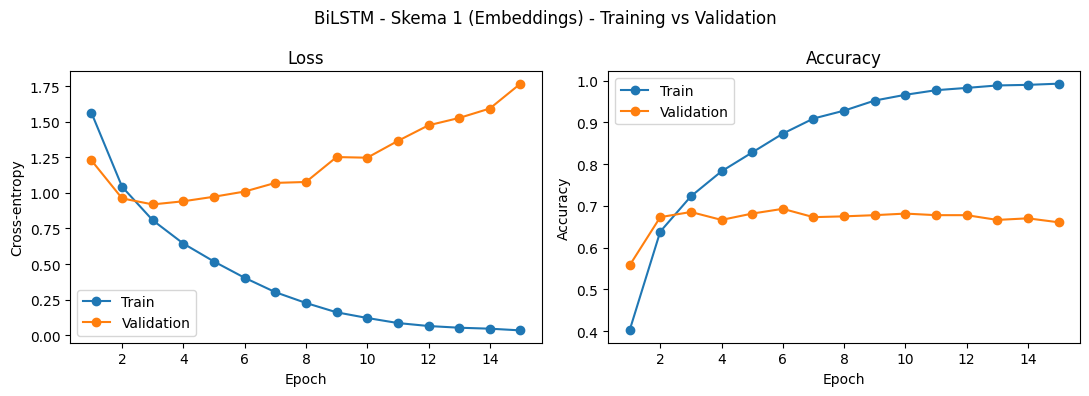

Val loss terendah di epoch 3 (0.9186); epoch terakhir: 1.7664


In [7]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"],   "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"],   "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("BiLSTM - Skema 1 (Embeddings) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06a_bilstm_embeddings_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [8]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in val_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(val_df[LABEL_COL] == kelas_terbanyak).mean():.4f}")
print(f"BiLSTM - Skema 1 (Embeddings) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)] # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
BiLSTM - Skema 1 (Embeddings) (val): accuracy = 0.6607 | macro-F1 = 0.6668


,precision,recall,f1-score,support
anger,0.7456,0.506,0.6028,168
fear,0.7623,0.6838,0.7209,136
joy,0.7219,0.5767,0.6412,189
love,0.5742,0.7876,0.6642,113
neutral,0.5857,0.6879,0.6327,298
sad,0.7117,0.7682,0.7389,151
accuracy,,,0.6607,1055
macro avg,0.6836,0.6684,0.6668,1055
weighted avg,0.6751,0.6607,0.6594,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,85,8,8,17,45,5
asli_fear,5,93,3,4,27,4
asli_joy,6,8,109,18,38,10
asli_love,2,0,5,89,13,4
asli_neutral,14,13,19,23,205,24
asli_sad,2,0,7,4,22,116


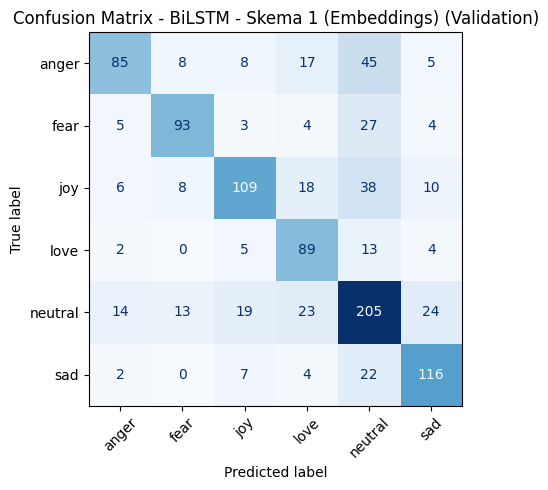

In [9]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - BiLSTM - Skema 1 (Embeddings) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06a_bilstm_embeddings_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [10]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "BiLSTM", "feature_extraction": "embeddings", "split": "validation",
                "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
                "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
                "extractor": "nn.Embedding level kata 128-dim (acak, trainable, end-to-end)",
                "emb_dim": int(EMB_DIM), "max_len": int(MAX_LEN), "vocab_size": int(VOCAB_SIZE),
                "epochs": EPOCHS, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/bilstm_embeddings_val_results.json


### Notes Part 6a:
- Vocabulary | MAX_LEN | parameter dilatih: 5716 | 64 | 997,382
- Train acc | Val acc (epoch terakhir): 0.9927 | 0.6607
- Val loss terendah di epoch: epoch ke-3 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.6607 | 0.6668
- Macro-Precision | Macro-Recall: 0.6836 | 0.6684
- F1 tertinggi | terendah per kelas: sad (0.7389) | anger (0.6028)
- Pasangan kelas yang paling sering tertukar: anger dan neutral (59 kesalahan di dua arah)
- Test set belum disentuh.